# Random Forests

*If one tree is wobbly, plant a forest: many slightly different trees, each with a 'vote'.*

:::{admonition} What we are going to do
:class: tip
At the end of the last chapter we found the weak spot of decision trees: they are **wobbly**. Give a tree slightly different data and it can come back quite different. In bias–variance language, a deep tree has **low bias but high variance**.

A **random forest** fixes this with a simple idea: grow **many** trees, make sure they are **different from each other**, and let them **vote** (classification) or **average** their answers (regression). We will see

1. the two sources of randomness that keep the trees different: **bootstrapping** the rows and **random feature selection** at each split,
2. how the trees' answers are combined (**bagging**), and how the left-out data gives us a free accuracy check (**out-of-bag** score),
3. how to judge a classifier across all thresholds with the **ROC curve** and **AUC**,
4. what **feature importance** tells us, and what it doesn't, and
5. where random forests sit in the wider family of **ensemble methods**.
:::

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, BaggingClassifier
from sklearn.linear_model import LinearRegression
from sklearn.datasets import make_moons, make_classification
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.inspection import permutation_importance

plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
GOLD, GREEN, LINE, RED, BLUE, GREY = "#e0a12a", "#4a9d5b", "#243b53", "#c0392b", "#2f6db3", "#8a8f98"

def plot_regions(ax, model, X, y, h=300, pad=0.5, alpha=0.35, s=16):
    x0, x1 = X[:, 0].min() - pad, X[:, 0].max() + pad
    y0, y1 = X[:, 1].min() - pad, X[:, 1].max() + pad
    xx, yy = np.meshgrid(np.linspace(x0, x1, h), np.linspace(y0, y1, h))
    zz = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5], colors=[GOLD, GREEN], alpha=alpha)
    ax.scatter(X[:, 0], X[:, 1], c=np.where(y == 0, GOLD, GREEN), s=s, edgecolor="white", lw=0.4)
    ax.set_xticks([]); ax.set_yticks([])

def box(ax, x, y, text, fc="white", ec=LINE, fs=9):
    ax.text(x, y, text, ha="center", va="center", fontsize=fs, zorder=3,
            bbox=dict(boxstyle="round,pad=0.4", fc=fc, ec=ec, lw=1.1))

def arrow(ax, p, q, label):
    ax.annotate("", xy=q, xytext=p, arrowprops=dict(arrowstyle="-|>", color=LINE, lw=1, shrinkA=15, shrinkB=15))
    ax.text((p[0] + q[0]) / 2 + (-0.06 if label == "Yes" else 0.06), (p[1] + q[1]) / 2, label,
            ha="center", va="center", fontsize=8.5, color=GREEN if label == "Yes" else RED)

## The wisdom of the crowd

Ask one person to guess the yield strength of an unfamiliar alloy and they may be far off. Ask fifty people and average their guesses, and the average is usually much closer, *as long as they did not all copy the same person*. Individual errors partly **cancel out**.

The same is true for models. Suppose we average $B$ models, each with prediction variance $\sigma^2$, and any two of them are correlated by an amount $\rho$ (between 0 and 1). The variance of the average is

$$
\operatorname{Var}(\text{average}) = \rho\,\sigma^2 + \frac{1-\rho}{B}\,\sigma^2 .
$$

(This formula assumes the models are equally variable and equally correlated; Note: You are not required to memorize the formula) Two lessons drop out of it:

- Adding **more models** (bigger $B$) shrinks the second term towards zero.
- The first term, $\rho\sigma^2$, does **not** shrink with more models. The only way to reduce it is to make the models **less alike** (smaller $\rho$).

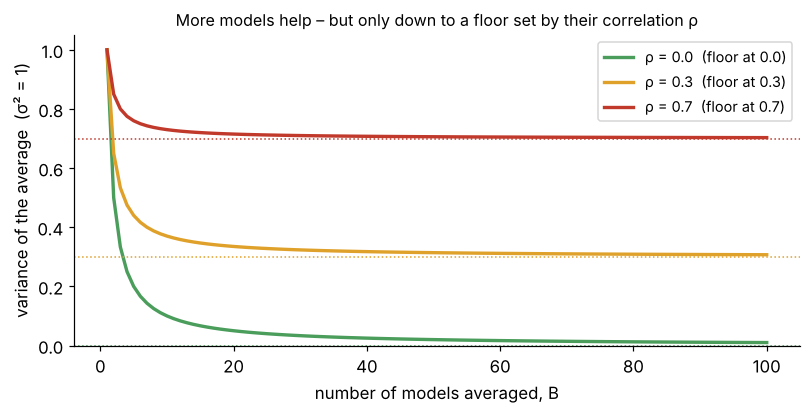

In [2]:
B = np.arange(1, 101)
fig, ax = plt.subplots(figsize=(7.5, 3.9))
for rho, col in zip([0.0, 0.3, 0.7], [GREEN, GOLD, RED]):
    ax.plot(B, rho + (1 - rho) / B, color=col, lw=2.2, label=f"ρ = {rho}  (floor at {rho})")
    ax.axhline(rho, color=col, ls=":", lw=1)
ax.set_xlabel("number of models averaged, B"); ax.set_ylabel("variance of the average  (σ² = 1)")
ax.set_ylim(0, 1.05); ax.legend(fontsize=9.5)
ax.set_title("More models help – but only down to a floor set by their correlation ρ", fontsize=10.5)
plt.tight_layout(); plt.show()

So a good crowd of trees needs two things: **many** trees, and trees that are **different** from one another. If we grew every tree on the same data with the same rules, they would all be identical ($\rho = 1$) and averaging would achieve nothing.

A random forest makes its trees different using **two ingredients of randomness**.

## Ingredient 1: give each tree its own data (bootstrapping)

Here is the small dataset used in the lecture: six samples (IDs 0-5), five features $x_0 \ldots x_4$, and a class label $y$ (0 or 1).

To build each tree, we do **not** use this table as it is. Instead we make a new table of the **same size** by drawing rows **at random, with replacement**. "With replacement" means a row goes back into the pot after it is drawn, so

- some rows appear **more than once**, and
- some rows are **left out** completely.

This resampling trick is called the **bootstrap** (Efron, 1979). Every tree gets its own bootstrap sample, so every tree sees slightly different data. These are the bootstrap samples used in the lecture for four trees:

In [3]:
data = pd.DataFrame(
    [[4.3, 4.9, 4.1, 4.7, 5.5, 0],
     [3.9, 6.1, 5.9, 5.5, 5.9, 0],
     [2.7, 4.8, 4.1, 5.0, 5.6, 0],
     [6.6, 4.4, 4.5, 3.9, 5.9, 1],
     [6.5, 2.9, 4.7, 4.6, 6.1, 1],
     [2.7, 6.7, 4.2, 5.3, 4.8, 1]],
    columns=["x0", "x1", "x2", "x3", "x4", "y"])
data.index.name = "ID"
display(data)

boot = {"T1": [2, 0, 2, 4, 5, 5], "T2": [2, 1, 3, 1, 4, 4],
        "T3": [4, 1, 3, 0, 0, 2], "T4": [3, 3, 2, 5, 1, 2]}
summary = pd.DataFrame({
    "rows drawn (with replacement)": [str(v) for v in boot.values()],
    "repeated": [sorted({i for i in v if v.count(i) > 1}) for v in boot.values()],
    "left out (out-of-bag)": [sorted(set(range(6)) - set(v)) for v in boot.values()]},
    index=boot.keys())
display(summary)

,x0,x1,x2,x3,x4,y
ID,,,,,,
0,4.3,4.9,4.1,4.7,5.5,0
1,3.9,6.1,5.9,5.5,5.9,0
2,2.7,4.8,4.1,5.0,5.6,0
3,6.6,4.4,4.5,3.9,5.9,1
4,6.5,2.9,4.7,4.6,6.1,1
5,2.7,6.7,4.2,5.3,4.8,1


,rows drawn (with replacement),repeated,left out (out-of-bag)
T1,"[2, 0, 2, 4, 5, 5]","[2, 5]","[1, 3]"
T2,"[2, 1, 3, 1, 4, 4]","[1, 4]","[0, 5]"
T3,"[4, 1, 3, 0, 0, 2]",[0],[5]
T4,"[3, 3, 2, 5, 1, 2]","[2, 3]","[0, 4]"


How many different rows does a bootstrap sample contain? Each draw misses a particular row with probability $1 - 1/n$, so after $n$ draws a row is missed with probability $(1 - 1/n)^n$. For large $n$ this approaches $e^{-1} \approx 0.368$. So, on average, a bootstrap sample contains about **63%** of the distinct rows, and about **37%** are left out. Those left-out rows will soon turn out to be very useful.

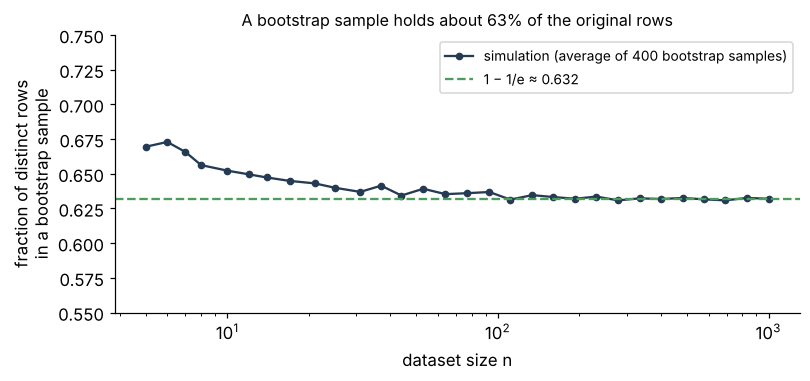

In [4]:
rng = np.random.default_rng(0)
ns = np.unique(np.logspace(np.log10(5), 3, 30).astype(int))
frac = [np.mean([len(np.unique(rng.integers(0, n, n))) / n for _ in range(400)]) for n in ns]
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(ns, frac, "o-", color=LINE, ms=4, label="simulation (average of 400 bootstrap samples)")
ax.axhline(1 - np.exp(-1), color=GREEN, ls="--", label="1 − 1/e ≈ 0.632")
ax.set_xscale("log"); ax.set_ylim(0.55, 0.75)
ax.set_xlabel("dataset size n"); ax.set_ylabel("fraction of distinct rows\nin a bootstrap sample")
ax.legend(fontsize=9); ax.set_title("A bootstrap sample holds about 63% of the original rows", fontsize=10.5)
plt.tight_layout(); plt.show()

## Ingredient 2: let each split see only a few features

Bootstrapping alone is not enough. Suppose one feature is much stronger than the others. Then almost every tree, whatever its bootstrap sample, will ask about that feature first, and the trees end up looking alike (high $\rho$).

So the random forest adds a second rule: **at every split, the tree may only choose from a small random subset of the features.** A new subset is drawn at **each node**, not once per tree. Strong features still get used often, but other features get their turn too, and the trees become more varied.

How many features per split? A common rule of thumb for classification is about $\sqrt{p}$ of the $p$ features. In the lecture example $p = 5$, and $\sqrt{5} \approx 2.2$, so each split chooses between about **2** randomly chosen features.

:::{note} What scikit-learn does by default
- `RandomForestClassifier`: `max_features="sqrt"`, i.e. $\sqrt{p}$ features per split.
- `RandomForestRegressor`: `max_features=1.0`, i.e. **all** features per split. With this default, the regressor uses only ingredient 1 (it is then simply bagged regression trees). A general guideline is about $p/3$ for regression, so it is worth tuning `max_features` for regression forests *(Ref: The Elements of Statistical Learning* (§15.3)).
:::

Putting both ingredients together, each tree in a random forest is built like this:

1. **Bootstrap** the training rows to make this tree's own dataset.
2. Grow a decision tree on it. **At each node**, pick a random subset of features, and find the best question **among those features only**.
3. Usually let the tree grow deep. Each tree overfits a little in its own way; the averaging will smooth that out.
4. Repeat for every tree in the forest.

## A forest by hand

Let's finish the lecture example. Each of the four trees below was grown on its own bootstrap sample from the table above. The numbers in each box are the $y$ labels of that tree's bootstrap rows that reach the box. The code computes them directly from the data, so you can check every box against the table.

⚠️  Note: You don't need to be able to draw the trees - this part is just visualization for better understanding. As long as you are able to build a Random Forest Classifier (or Regressor) similar to how we built all other models, and reach a prediction - that is what is required.

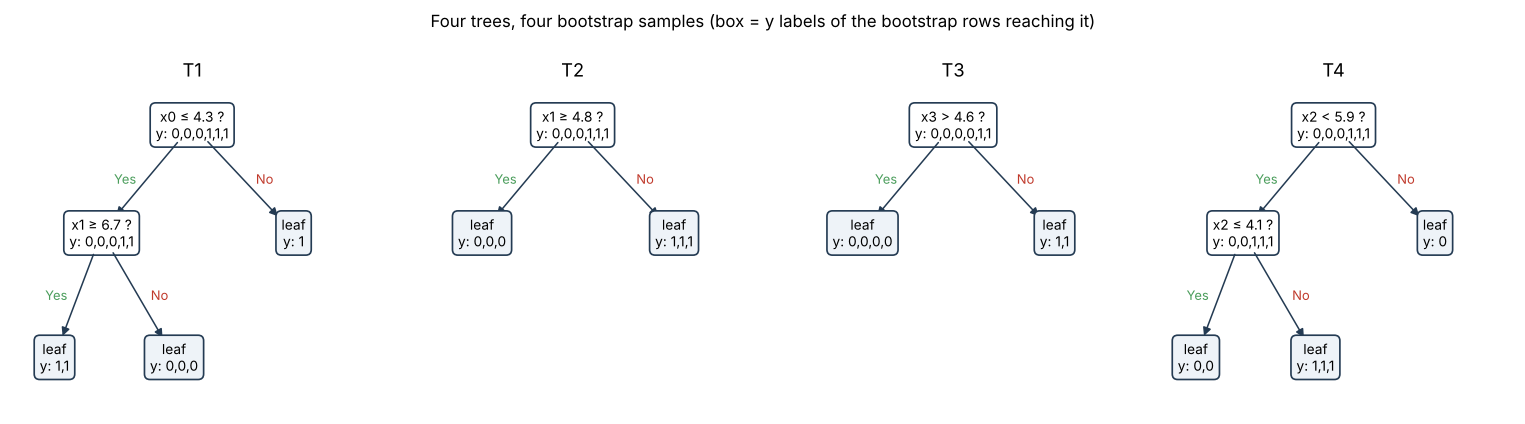

Test sample ID 6: x0 = 3.8, x1 = 6.8, x2 = 5.2, x3 = 4.9, x4 = 3.1


tree,T1,T2,T3,T4
prediction for test sample ID 6,1,0,0,1


Votes for class 0: 2    Votes for class 1: 2


In [5]:
import operator
OPS = {"≤": operator.le, "≥": operator.ge, ">": operator.gt, "<": operator.lt}
# each tree: root question, and (optionally) a second question on the "Yes" branch
trees = {"T1": [("x0", "≤", 4.3), ("x1", "≥", 6.7)],
         "T2": [("x1", "≥", 4.8)],
         "T3": [("x3", ">", 4.6)],
         "T4": [("x2", "<", 5.9), ("x2", "≤", 4.1)]}

def labels(df):
    return ",".join(str(v) for v in sorted(df["y"])) or "–"

def vote(df):
    return int(round(df["y"].mean()))      # majority label in a (pure) leaf

test = pd.Series({"x0": 3.8, "x1": 6.8, "x2": 5.2, "x3": 4.9, "x4": 3.1})
fig, axes = plt.subplots(1, 4, figsize=(14, 3.9))
results = []
for ax, (name, qs) in zip(axes, trees.items()):
    d = data.loc[boot[name]]
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis("off"); ax.set_title(name, fontsize=12)
    f, op, t = qs[0]; yes = d[OPS[op](d[f], t)]; no = d[~OPS[op](d[f], t)]
    box(ax, 0.5, 0.88, f"{f} {op} {t} ?\ny: {labels(d)}")
    arrow(ax, (0.5, 0.88), (0.25, 0.55), "Yes"); arrow(ax, (0.5, 0.88), (0.78, 0.55), "No")
    box(ax, 0.78, 0.55, f"leaf\ny: {labels(no)}", fc="#eef3f8")
    path = [OPS[op](test[f], t)]
    if len(qs) == 1:
        box(ax, 0.25, 0.55, f"leaf\ny: {labels(yes)}", fc="#eef3f8")
        leaf = yes if path[0] else no
    else:
        f2, op2, t2 = qs[1]; yes2 = yes[OPS[op2](yes[f2], t2)]; no2 = yes[~OPS[op2](yes[f2], t2)]
        box(ax, 0.25, 0.55, f"{f2} {op2} {t2} ?\ny: {labels(yes)}")
        arrow(ax, (0.25, 0.55), (0.12, 0.17), "Yes"); arrow(ax, (0.25, 0.55), (0.45, 0.17), "No")
        box(ax, 0.12, 0.17, f"leaf\ny: {labels(yes2)}", fc="#eef3f8")
        box(ax, 0.45, 0.17, f"leaf\ny: {labels(no2)}", fc="#eef3f8")
        leaf = (yes2 if OPS[op2](test[f2], t2) else no2) if path[0] else no
    results.append({"tree": name, "prediction for test sample ID 6": vote(leaf)})
plt.suptitle("Four trees, four bootstrap samples (box = y labels of the bootstrap rows reaching it)", fontsize=11)
plt.tight_layout(); plt.show()

print("Test sample ID 6:", ", ".join(f"{k} = {v}" for k, v in test.items()))
votes = pd.DataFrame(results).set_index("tree")
display(votes.T)
counts = votes.iloc[:, 0].value_counts().sort_index()
print("Votes for class 0:", counts.get(0, 0), "   Votes for class 1:", counts.get(1, 0))

Notice how different the four trees are, even though they come from the same six rows. Each one saw different data, and each asks about different features.

Now a new sample arrives (ID 6: $x_0 = 3.8,\ x_1 = 6.8,\ x_2 = 5.2,\ x_3 = 4.9,\ x_4 = 3.1$). Drop it down each tree:

- **T1:** $x_0 = 3.8 \le 4.3$ → Yes; $x_1 = 6.8 \ge 6.7$ → Yes → leaf "1,1" → **1**
- **T2:** $x_1 = 6.8 \ge 4.8$ → Yes → leaf "0,0,0" → **0**
- **T3:** $x_3 = 4.9 > 4.6$ → Yes → leaf "0,0,0,0" → **0**
- **T4:** $x_2 = 5.2 < 5.9$ → Yes; $5.2 \le 4.1$ → No → leaf "1,1,1" → **1**

That is **two votes for 1 and two for 0**: a tie! This is a useful reminder of two practical points:

- Real forests use **many** trees (the `scikit-learn` default is 100), so exact ties become very rare.
- `scikit-learn` does not actually count hard votes. Each tree reports class **probabilities** (the class fractions in its leaf), and the forest predicts the class with the highest **average probability** ("soft voting"). In an exact tie it falls back to the first class.

*Note: One of the trees had a minor error in the lecture: which has been corrected in the lecture notes (which is the same as shown here)*

## Combining the trees: bagging

The forest's final answer is an **aggregate** of all the trees:

- **Classification:** majority vote, or (as in `scikit-learn`) the class with the highest average probability.
- **Regression:** the **average** of the trees' numerical predictions.

**B**ootstrap + **agg**regat**ing** is called **bagging** (Breiman, 1996). A random forest is bagging *plus* random feature selection at each split (Breiman, 2001).

The figure compares one deep tree, plain bagging (bootstrap only), and a random forest on the noisy data from the last chapter:

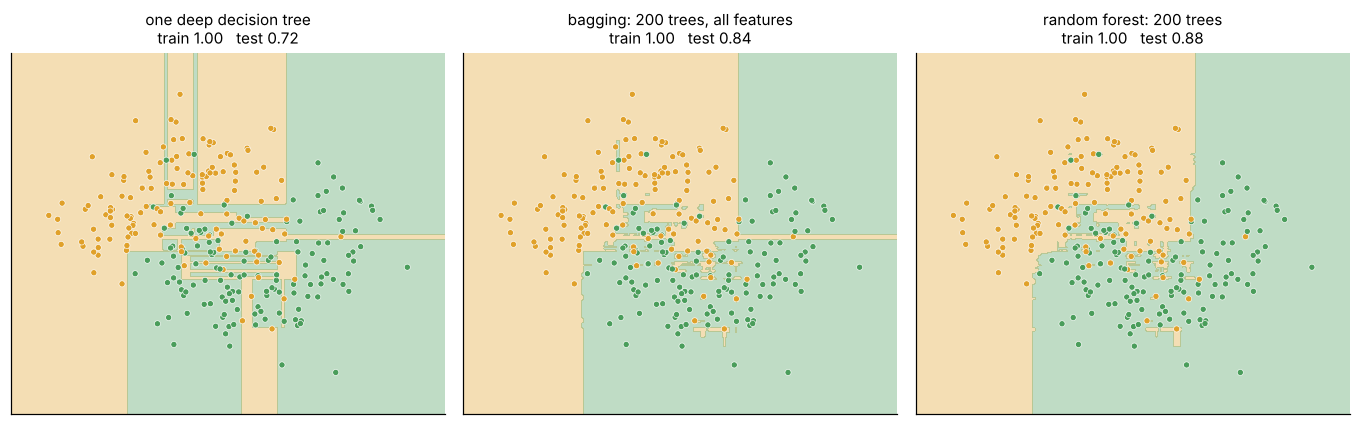

In [6]:
Xm, ym = make_moons(n_samples=400, noise=0.4, random_state=0)
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(Xm, ym, test_size=0.3, stratify=ym, random_state=0)
models = {"one deep decision tree": DecisionTreeClassifier(random_state=0),
          "bagging: 200 trees, all features": BaggingClassifier(DecisionTreeClassifier(), n_estimators=200, random_state=0),
          "random forest: 200 trees": RandomForestClassifier(n_estimators=200, random_state=0)}
fig, axes = plt.subplots(1, 3, figsize=(12.5, 4.0), sharex=True, sharey=True)
for ax, (name, m) in zip(axes, models.items()):
    m.fit(Xm_tr, ym_tr); plot_regions(ax, m, Xm_tr, ym_tr)
    ax.set_title(f"{name}\ntrain {m.score(Xm_tr, ym_tr):.2f}   test {m.score(Xm_te, ym_te):.2f}", fontsize=10)
plt.tight_layout(); plt.show()

All three score 100% on the training data, because their trees are grown deep. But the **averaged** models draw smoother boundaries with fewer isolated islands, and they do clearly better on the test set than the single tree. With only two features, the random forest considers just **one** randomly chosen feature at each split; that extra randomness makes its trees more varied than bagging's, and here it scores a little higher still. (With 120 test samples, treat small gaps like 0.84 versus 0.88 with some caution.)

## A free validation set: the out-of-bag score

Remember that each tree never sees about 37% of the training rows. For each training row, we can collect the predictions of **only those trees that did not see it**, and check whether they get it right. Averaged over all rows, this gives the **out-of-bag (OOB) score**.

The OOB score behaves much like a cross-validation score, but it comes **for free** while the forest is being trained, with no extra splitting. In `scikit-learn`, ask for it with `RandomForestClassifier(oob_score=True)` and read it from `.oob_score_`. (For the bootstrap rows of the lecture example, the OOB rows were listed in the table above: for instance, rows 1 and 3 for tree T1.)

## Putting it to work 💪

The lecture uses the superconductivity dataset for this step. Here we use a **made-up** stand-in so that we know the right answers in advance.

Imagine we want to predict whether a compound is a "high-$T_c$" superconductor (class 1) or not (class 0) from eight composition-based descriptors, `d1` to `d8`. The data are **synthetic**: we built them so that

- `d1`, `d2`, `d3` genuinely carry information about the class,
- `d4` is a mixture of `d1`-`d3` (redundant: it carries no new information),
- `d5`-`d8` are pure **noise**, and
- about 5% of the labels are flipped at random.

The workflow follows the lecture's steps: read the data, split, initialise `RandomForestClassifier()`, train, predict, evaluate. One step from the lecture is deliberately left out: **standardisation**. As we saw last chapter, trees (and therefore forests) give the same results with or without it.

In [7]:
import numpy as np
import pandas as pd
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score

# --- a MADE-UP dataset: 600 "compounds", 8 descriptors, class 1 = "high-Tc" ---
X, y = make_classification(n_samples=600, n_features=8, n_informative=3, n_redundant=1,
                           n_repeated=0, flip_y=0.05, class_sep=1.0, shuffle=False, random_state=0)
X = pd.DataFrame(X, columns=[f"d{i}" for i in range(1, 9)])    # d1-d3 informative, d4 redundant, d5-d8 noise

# 1. split (stratify keeps the class balance the same in both sets)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)

# 2. a single deep tree, for comparison
tree = DecisionTreeClassifier(random_state=0).fit(X_train, y_train)

# 3. the random forest: 300 trees, out-of-bag score switched on
forest = RandomForestClassifier(n_estimators=300, oob_score=True, random_state=0, n_jobs=-1)
forest.fit(X_train, y_train)

# 4. predict and evaluate
y_pred = forest.predict(X_test)
p_test = forest.predict_proba(X_test)[:, 1]          # probability of class 1, used for the ROC curve
print(f"{'':14s}{'train':>8s}{'test':>8s}{'AUC':>8s}")
for name, m in [("single tree", tree), ("random forest", forest)]:
    print(f"{name:14s}{m.score(X_train, y_train):8.3f}{m.score(X_test, y_test):8.3f}"
          f"{roc_auc_score(y_test, m.predict_proba(X_test)[:, 1]):8.3f}")
print(f"\nOut-of-bag accuracy of the forest: {forest.oob_score_:.3f}\n")
print(classification_report(y_test, y_pred, target_names=["low-Tc (0)", "high-Tc (1)"]))

                 train    test     AUC
single tree      1.000   0.813   0.813


random forest    1.000   0.860   0.936

Out-of-bag accuracy of the forest: 0.844

              precision    recall  f1-score   support

  low-Tc (0)       0.89      0.83      0.86        75
 high-Tc (1)       0.84      0.89      0.86        75

    accuracy                           0.86       150
   macro avg       0.86      0.86      0.86       150
weighted avg       0.86      0.86      0.86       150



How to read this:

- **Both models score 100% on the training data.** That is normal for deep trees, and it tells us nothing about new data.
- **The forest beats the single tree on the test set**, and by even more on **AUC** (explained next). AUC rewards a model for *ranking* samples well, and averaging hundreds of trees gives much better-graded probabilities than one tree, whose leaves are mostly pure and therefore say only "0%" or "100%".
- **The out-of-bag accuracy is close to the test accuracy**, without using the test set at all. In practice, this is handy for tuning when data are scarce.
- The **classification report** gives precision, recall and F1 for each class, as in the SVM chapter.

## Judging a classifier at every threshold: the ROC curve

A random forest does not just say "class 1". It gives a **probability**, and `predict` turns that into a label using a **threshold** of 0.5. But 0.5 is not sacred. If missing a promising superconductor is costly, we might flag every compound with a probability above 0.3; if lab time is precious, we might only test those above 0.8.

Every threshold gives a different trade-off between

- the **True Positive Rate** (TPR, also called recall): the fraction of real class-1 samples that we flag, and
- the **False Positive Rate** (FPR): the fraction of real class-0 samples that we wrongly flag.

The **ROC curve** (Receiver Operating Characteristic) plots TPR against FPR as the threshold slides from 1 down to 0.

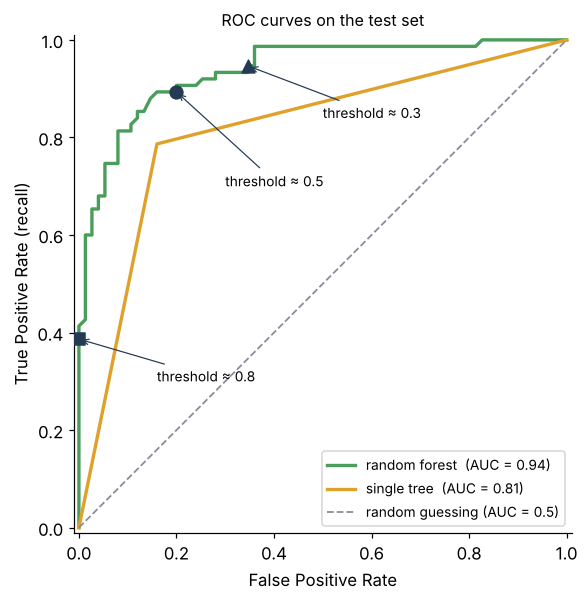

In [8]:
fig, ax = plt.subplots(figsize=(6.4, 5.6))
for name, m, col in [("random forest", forest, GREEN), ("single tree", tree, GOLD)]:
    p = m.predict_proba(X_test)[:, 1]
    fpr, tpr, thr = roc_curve(y_test, p)
    ax.plot(fpr, tpr, color=col, lw=2.2, label=f"{name}  (AUC = {roc_auc_score(y_test, p):.2f})")
fpr, tpr, thr = roc_curve(y_test, p_test)
for t, mk, txt in [(0.8, "s", (0.16, 0.30)), (0.5, "o", (0.30, 0.70)), (0.3, "^", (0.50, 0.84))]:
    i = np.argmin(np.abs(thr - t))
    ax.scatter(fpr[i], tpr[i], s=70, marker=mk, color=LINE, zorder=4)
    ax.annotate(f"threshold ≈ {t}", (fpr[i], tpr[i]), xytext=txt, fontsize=9,
                arrowprops=dict(arrowstyle="->", color=LINE, lw=0.8))
ax.plot([0, 1], [0, 1], "--", color=GREY, lw=1.2, label="random guessing (AUC = 0.5)")
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate (recall)")
ax.set_xlim(-0.01, 1.01); ax.set_ylim(-0.01, 1.01); ax.set_aspect("equal")
ax.legend(fontsize=9, loc="lower right"); ax.set_title("ROC curves on the test set", fontsize=10.5)
plt.tight_layout(); plt.show()

How to read an ROC curve:

- **Top-left corner is best**: lots of true positives, few false positives. A curve that hugs the top-left corner belongs to a good classifier.
- **The diagonal is random guessing.** A curve below it is worse than random (flip the predictions!).
- **Sliding along the curve** = changing the threshold. Lowering it from 0.8 to 0.3 catches more real positives (up) but also flags more false ones (right).
- The single tree's "curve" has only a couple of corners because its probabilities are nearly all 0 or 1.

:::{admonition} Careful: which threshold?
:class: warning
The ROC threshold is the cut-off on the model's **predicted probability**. It is *not* the cut-off used to define the classes in the first place. If we change the definition of "high-$T_c$" from 30 K to 77 K, we change the **labels** in the data. That is a **new classification problem**, which needs its own model and has its own ROC curve.
:::

### Area under the curve (AUC)

The **AUC** squeezes the whole curve into one number between 0 and 1. It has a friendly meaning: **the AUC is the probability that a randomly chosen positive sample gets a higher score than a randomly chosen negative one.**

- AUC = 1: perfect ranking.
- AUC = 0.5: no better than coin-flipping.

A widely quoted rule of thumb (Hosmer, Lemeshow & Sturdivant, 2013) reads:

| AUC | Discrimination |
|---|---|
| 0.5 | none |
| 0.5 – 0.7 | poor |
| 0.7 – 0.8 | acceptable |
| 0.8 – 0.9 | excellent |
| ≥ 0.9 | outstanding |

Treat any such scale as a rough guide only. What counts as "good enough" depends on the application, and when one class is very rare, a precision - recall curve is often more informative than the ROC curve.

## Which features does the forest rely on?

### Impurity-based importance (MDI)

Every time a tree splits on a feature, the Gini impurity drops (that is why the split was chosen). Add up those drops for each feature, weighting each by the number of samples it affects, average over all trees, and scale the totals so they **sum to 1**. That is the **impurity-based** or **Gini importance**, also called **mean decrease in impurity (MDI)**. In `scikit-learn` it is `forest.feature_importances_`. (For regression forests, the drop in squared error is used instead of Gini.)

The values are **relative**: a feature with importance 0.4 contributed twice as much impurity reduction as one with 0.2.

### Permutation importance

A second, more direct check: take the **test set**, randomly **shuffle one column** (breaking its link with the target - and messing up the meaning in the dataset), and see how much the score drops. A feature the model truly relies on causes a big drop; a useless one causes none.

Because we built this dataset ourselves, we know the right answer: `d1`-`d3` matter, `d4` is a redundant mix of them, and `d5`–`d8` are noise. Let's see how the two methods do.

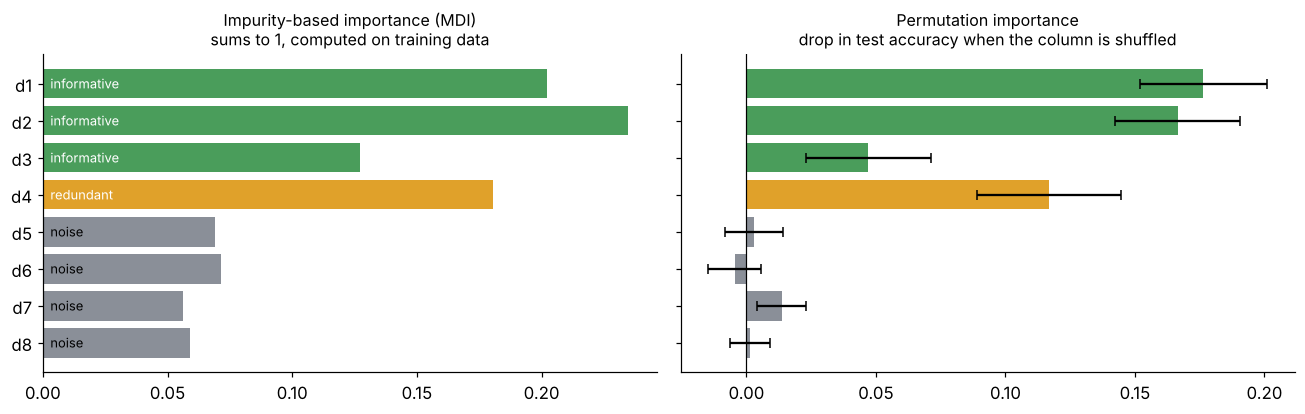

,MDI (training data),permutation (test data),perm_sd
d1,0.202,0.176,0.024
d2,0.235,0.166,0.024
d3,0.127,0.047,0.024
d4,0.180,0.117,0.028
d5,0.069,0.003,0.011
d6,0.071,-0.004,0.010
d7,0.056,0.014,0.010
d8,0.059,0.001,0.008


Total MDI given to the four pure-noise features: 0.26


In [9]:
perm = permutation_importance(forest, X_test, y_test, n_repeats=30, random_state=0, n_jobs=-1)
imp = pd.DataFrame({"MDI (training data)": forest.feature_importances_,
                    "permutation (test data)": perm.importances_mean,
                    "perm_sd": perm.importances_std}, index=X.columns)
truth = ["informative"] * 3 + ["redundant"] + ["noise"] * 4
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9), sharey=True)
colors = [GREEN] * 3 + [GOLD] + [GREY] * 4
axes[0].barh(X.columns, imp["MDI (training data)"], color=colors)
axes[1].barh(X.columns, imp["permutation (test data)"], xerr=imp["perm_sd"], color=colors, capsize=3)
axes[0].set_title("Impurity-based importance (MDI)\nsums to 1, computed on training data", fontsize=10.5)
axes[1].set_title("Permutation importance\ndrop in test accuracy when the column is shuffled", fontsize=10.5)
axes[1].axvline(0, color="black", lw=0.8)
axes[0].invert_yaxis()
for k, lab in enumerate(truth):
    axes[0].text(0.003, k, lab, va="center", fontsize=8.5, color="white" if lab != "noise" else "black")
plt.tight_layout(); plt.show()
display(imp.round(3))
print(f"Total MDI given to the four pure-noise features: {imp.iloc[4:, 0].sum():.2f}")

What do we learn?

- **Both methods put d1 and d2 at the top**. Good. d3 is genuinely informative too, but it adds less: on its own it is no better than a coin flip, yet adding it to d1 and d2 lifts cross-validated accuracy from about 0.83 to 0.90. Some of its credit is also taken by d4, which is partly built from it.
- **MDI hands about a quarter of the total importance to the four pure-noise features.** Deep trees keep splitting on noise to fit the training data perfectly, and MDI, which is computed **on the training data**, credits every one of those splits. **Permutation importance on the test set** correctly gives the noise features almost zero.
- **The redundant feature `d4` looks important** to both methods, even though it carries no new information. When features are correlated, importance gets **shared** between them, and the redundant feature can even appear more important than the "real" ones.

Some cautions worth remembering:

- MDI can be biased towards features with **many distinct values** (continuous features, or ID-like columns) over features with few values (Strobl *et al.*, 2007). The `scikit-learn` documentation warns about this and recommends permutation importance as an alternative.
- Importance describes **what this model used**, not what **causes** the property. A descriptor can be "important" just because it is correlated with the real physical driver.
- Feature importance comes from a **supervised** model trained to predict a target. It is not a tool for clustering.

## Missing values and messy data

Random forests are often said to "handle missing data". That needs a little care.

- **What is true:** recent versions of `scikit-learn` (1.4 and later) let `RandomForestClassifier` and `RandomForestRegressor` train and predict on data containing `NaN`. At each split, the tree learns whether samples with a missing value should go left or right. Older versions raise an error if there are any `NaN`s. (Breiman and Cutler's original random forest software took a different route: it filled in missing values, either with class medians or with an iterative method based on how often samples land in the same leaves.)
- **What is not true:** that a random forest makes data cleaning unnecessary. A forest cannot tell that a yield strength of -250 MPa is a sign error, that two rows are duplicates, that a temperature was recorded in °F instead of °C, or that the same alloy appears in both the training and test sets. Everything from the data-cleaning week (and Assignment 1) still applies.

A quick demonstration: we hide 10% of the descriptor values at random and train again.

In [10]:
rng = np.random.default_rng(0)
X_train_nan, X_test_nan = X_train.copy(), X_test.copy()
X_train_nan[rng.random(X_train.shape) < 0.10] = np.nan
X_test_nan[rng.random(X_test.shape) < 0.10] = np.nan
forest_nan = RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1).fit(X_train_nan, y_train)
print(f"missing values in training set : {int(X_train_nan.isna().sum().sum())} of {X_train_nan.size}")
print(f"test accuracy, complete data   : {forest.score(X_test, y_test):.3f}")
print(f"test accuracy, 10% values NaN  : {forest_nan.score(X_test_nan, y_test):.3f}")

missing values in training set : 371 of 3600
test accuracy, complete data   : 0.860
test accuracy, 10% values NaN  : 0.813


The forest trains without complaint. Test accuracy drops a little (from 0.86 to 0.81), which is not surprising: a tenth of the information has simply been removed. Convenient, but notice that we *chose* to hide values completely at random. In real lab data, values are often missing for a **reason** (the measurement failed for the hardest samples, say), and no algorithm can fix that for you.

## How many trees?

More trees make the average steadier. Unlike a deeper tree, **adding trees does not make a forest overfit**: the test and OOB scores rise quickly at first, then improve only slowly, and they do not turn down. Beyond a few hundred trees, extra trees mostly cost computing time.

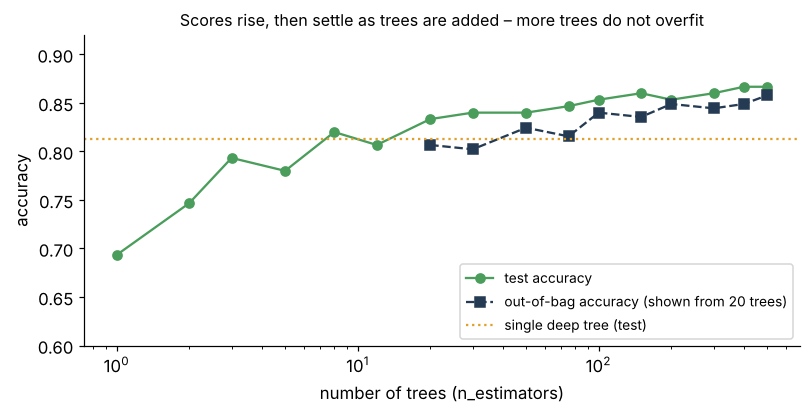

In [11]:
n_list = [1, 2, 3, 5, 8, 12, 20, 30, 50, 75, 100, 150, 200, 300, 400, 500]
te_acc, oob_acc = [], []
for n in n_list:
    m = RandomForestClassifier(n_estimators=n, oob_score=n >= 20, random_state=0, n_jobs=-1).fit(X_train, y_train)
    te_acc.append(m.score(X_test, y_test)); oob_acc.append(m.oob_score_ if n >= 20 else np.nan)
fig, ax = plt.subplots(figsize=(7.5, 3.9))
ax.plot(n_list, te_acc, "o-", color=GREEN, label="test accuracy")
ax.plot(n_list, oob_acc, "s--", color=LINE, label="out-of-bag accuracy (shown from 20 trees)")
ax.axhline(tree.score(X_test, y_test), color=GOLD, ls=":", label="single deep tree (test)")
ax.set_xscale("log"); ax.set_xlabel("number of trees (n_estimators)"); ax.set_ylabel("accuracy")
ax.legend(fontsize=9, loc="lower right"); ax.set_ylim(0.6, 0.92)
ax.set_title("Scores rise, then settle as trees are added – more trees do not overfit", fontsize=10.5)
plt.tight_layout(); plt.show()

(With very few trees, many training rows are not out-of-bag for *any* tree, so the OOB score is unreliable there; `scikit-learn` warns about this, which is why the curve starts at 20 trees.)

What *can* still make a forest overfit is the size of each individual tree. That is controlled by the same settings as for a single tree (`max_depth`, `min_samples_leaf`, …).

## A warning for materials discovery: forests cannot extrapolate

Every prediction of a regression forest is an average of leaf values, and every leaf value is an average of **training** targets. So a forest can never predict a value **outside the range of the training data**. Below, a forest and a straight line are trained on the same made-up data (x from 0 to 5) and asked to predict up to x = 8:

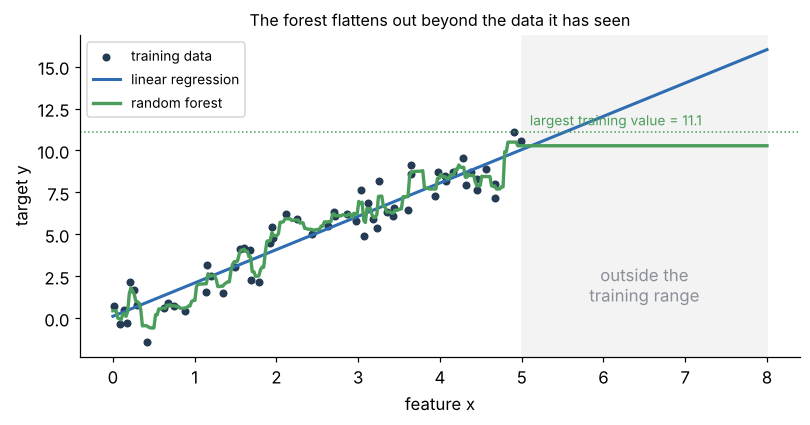

In [12]:
rng = np.random.default_rng(0)
x_tr = rng.uniform(0, 5, 60).reshape(-1, 1)
y_tr = 2.0 * x_tr.ravel() + rng.normal(0, 1.0, 60)            # invented linear trend + noise
x_all = np.linspace(0, 8, 400).reshape(-1, 1)
rf_reg = RandomForestRegressor(n_estimators=300, random_state=0).fit(x_tr, y_tr)
lin = LinearRegression().fit(x_tr, y_tr)
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.axvspan(5, 8, color="#f3f3f3", zorder=0); ax.text(6.5, 1, "outside the\ntraining range", ha="center", color=GREY)
ax.scatter(x_tr, y_tr, s=18, color=LINE, label="training data")
ax.plot(x_all, lin.predict(x_all), color=BLUE, lw=2, label="linear regression")
ax.plot(x_all, rf_reg.predict(x_all), color=GREEN, lw=2.2, label="random forest")
ax.axhline(y_tr.max(), color=GREEN, ls=":", lw=1)
ax.text(5.1, y_tr.max() + 0.4, f"largest training value = {y_tr.max():.1f}", color=GREEN, fontsize=9)
ax.set_xlabel("feature x"); ax.set_ylabel("target y"); ax.legend(fontsize=9, loc="upper left")
ax.set_title("The forest flattens out beyond the data it has seen", fontsize=10.5)
plt.tight_layout(); plt.show()

Inside the training range, the forest is excellent. Outside it, the forest flattens out, because it has nothing to average but the values it has already seen. This matters whenever we hope to find a material **better than anything in the training set**: a higher $T_c$, a stronger alloy, a better catalyst. Meredig *et al.* (2018) showed exactly this for superconductors: when whole families of high-$T_c$ compounds were held out of training, a random forest could not predict that those families would be high-$T_c$.

The fix is not a different random seed. It is a different strategy: validate in a way that mimics discovery (for example, holding out whole material families), and combine predictions with **uncertainty**, as we did with Gaussian processes and Bayesian optimisation.

## The main settings (hyperparameters)

| Hyperparameter | What it controls | Default in scikit-learn | Tips |
|---|---|---|---|
| `n_estimators` | number of trees | 100 | more is steadier, never worse, only slower; a few hundred is usually plenty |
| `max_features` | features to choose from at each split | `"sqrt"` (classifier), `1.0` (regressor) | the most useful one to tune: smaller = more varied trees |
| `max_depth`, `min_samples_leaf` | size of each tree | grow fully, 1 sample per leaf | larger `min_samples_leaf` smooths predictions; helps with noisy data |
| `bootstrap`, `max_samples` | whether, and how much, to resample rows | `True`, same size as the data | rarely changed |
| `class_weight` | extra weight for rare classes | `None` | try `"balanced"` for imbalanced data, as with SVMs |
| `criterion` | how splits are scored | `"gini"` (classifier), `"squared_error"` (regressor) | `"entropy"` gives very similar results |
| `oob_score` | compute the out-of-bag score | `False` | switch on for a free validation estimate |
| `n_jobs` | CPU cores to use | `None` (one core) | `-1` uses all cores (trees are built independently) |

Random forests often work well **straight out of the box**. For a robust model, tune `max_features` and `min_samples_leaf` with **cross-validation** (or the OOB score).

## Strengths and limitations

**Strengths**

- Strong accuracy with little tuning; a good **first model** to try on tabular materials data.
- Captures **non-linear** effects and **interactions** between features automatically.
- **No feature scaling** needed, and not bothered by outliers in the *features* (only their order matters).
- Built-in **OOB** estimate and **feature importances**.
- Trees are independent, so training runs nicely in **parallel**.

**Limitations**

- **Cannot extrapolate** beyond the range of the training targets.
- Much **less interpretable** than a single tree: you cannot read 300 trees.
- **Memory and prediction time** grow with the number and depth of trees.
- Feature importances need care: they can be biased (MDI) and they do not imply causation.
- Categorical features must be encoded first in `scikit-learn`, and cleaning the data is still your job.

## The wider family: ensemble methods

A random forest is one example of an **ensemble**: a model built by combining many other models (the **base learners**).

- **Homogeneous ensembles** combine many learners of the **same type**, usually trees. This is by far the most common kind.
- **Heterogeneous ensembles** combine **different** models (say, an SVM, a random forest and a Gaussian process) by voting or by training a final model on their outputs ("stacking"). These are less common.

The homogeneous tree ensembles come in two main styles:

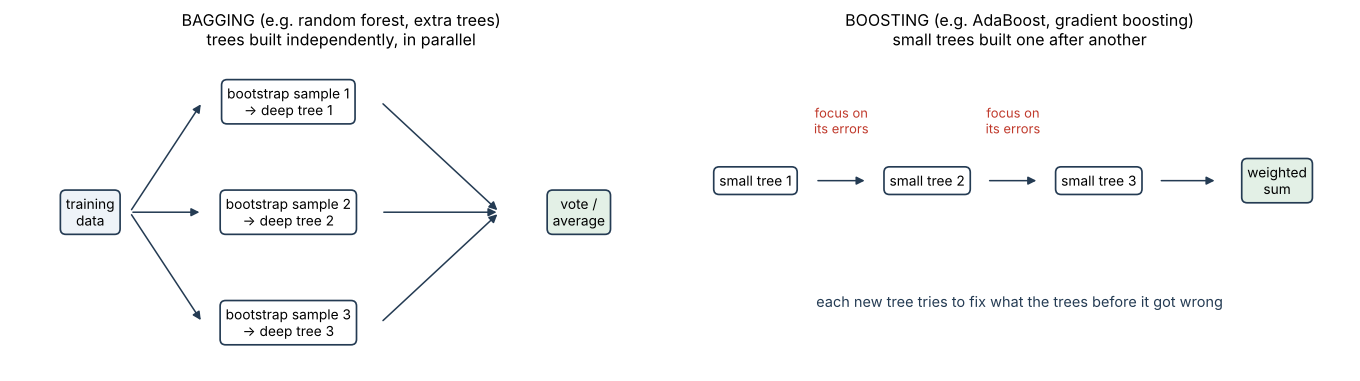

In [13]:
fig, (a, b) = plt.subplots(1, 2, figsize=(12.5, 3.6))
for ax in (a, b): ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis("off")
a.set_title("BAGGING (e.g. random forest, extra trees)\ntrees built independently, in parallel", fontsize=10.5)
box(a, 0.12, 0.5, "training\ndata", fc="#eef3f8")
for k, yy in enumerate([0.85, 0.5, 0.15]):
    box(a, 0.42, yy, f"bootstrap sample {k + 1}\n→ deep tree {k + 1}")
    a.annotate("", xy=(0.29, yy), xytext=(0.18, 0.5), arrowprops=dict(arrowstyle="-|>", color=LINE))
    a.annotate("", xy=(0.74, 0.5), xytext=(0.56, yy), arrowprops=dict(arrowstyle="-|>", color=LINE))
box(a, 0.86, 0.5, "vote /\naverage", fc="#e3f0e6")
b.set_title("BOOSTING (e.g. AdaBoost, gradient boosting)\nsmall trees built one after another", fontsize=10.5)
xs = [0.1, 0.36, 0.62]
for k, xx in enumerate(xs):
    box(b, xx, 0.6, f"small tree {k + 1}")
    if k < 2:
        b.annotate("", xy=(xs[k + 1] - 0.09, 0.6), xytext=(xx + 0.09, 0.6), arrowprops=dict(arrowstyle="-|>", color=LINE))
        b.text((xx + xs[k + 1]) / 2, 0.75, "focus on\nits errors", ha="center", fontsize=8.5, color=RED)
b.annotate("", xy=(0.80, 0.6), xytext=(0.71, 0.6), arrowprops=dict(arrowstyle="-|>", color=LINE))
box(b, 0.89, 0.6, "weighted\nsum", fc="#e3f0e6")
b.text(0.5, 0.2, "each new tree tries to fix what the trees before it got wrong", ha="center", fontsize=9.5, color=LINE)
plt.tight_layout(); plt.show()

**Bagging-style ensembles** (the random forest family) build many **deep, low-bias, high-variance** trees **independently** and average them to cut the **variance**.

- **Random forest** - bootstrap rows + random feature subset at each split (Breiman, 2001).
- **Extremely randomised trees ("Extra Trees")** - a close cousin. By default it uses **no bootstrapping** (every tree sees all the training rows), and it adds even more randomness: for each candidate feature it draws the cut point **at random**, then keeps the best of those random cuts (Geurts, Ernst & Wehenkel, 2006). In `scikit-learn`: `ExtraTreesClassifier` / `ExtraTreesRegressor`.

**Boosting** works the other way round. It builds **small, high-bias** trees **one after another**, each one concentrating on the mistakes of those before it, so the ensemble steadily reduces the **bias**. Boosting methods are tree ensembles, but they are *not* random forests.

- **AdaBoost** (Freund & Schapire, 1997) - usually uses **stumps** (a tree with one question and two leaves). After each round, the samples that were misclassified get **larger weights** (or are drawn more often when resampling), so the next stump pays more attention to them. Each stump also gets an amount of "say" in the final vote that depends on how accurate it was.
- **Gradient boosting** (Friedman, 2001) - each new tree is fitted to the **remaining errors** (the residuals; more generally, the gradient of the loss) of the ensemble so far, and added with a small learning rate. Popular implementations include `HistGradientBoostingClassifier` in `scikit-learn`, XGBoost and LightGBM. For example, a widely used superconductivity study of 21,263 compounds described by 81 features used gradient-boosted trees (XGBoost) to predict $T_c$ (Hamidieh, 2018).

**A guideline that ties it together (bias–variance again):** if your base learner has **high variance and low bias** (deep trees), combine them by **averaging** (bagging, random forests). If it has **high bias and low variance** (stumps, shallow trees), combine them **sequentially** to reduce the bias (boosting).

## Putting it together

- A **random forest** is a crowd of decision trees whose answers are combined by **voting** (classification) or **averaging** (regression).
- Averaging only helps if the trees are **different**. Two sources of randomness make them so: a **bootstrap sample** of the rows for each tree, and a **random subset of features at every split**.
- Bootstrap + aggregate = **bagging**. The ~37% of rows each tree never sees give a free **out-of-bag** accuracy estimate.
- More trees do not cause overfitting; the scores settle. Tune `max_features` and `min_samples_leaf` with cross-validation or OOB.
- The **ROC curve** shows the TPR/FPR trade-off as the **probability threshold** changes; the **AUC** summarises it (0.5 = random, 1 = perfect ranking).
- **Feature importances** (MDI) are quick but can mislead; check them with **permutation importance** on held-out data, and never read them as causes.
- Forests **cannot extrapolate** beyond the training targets, which is a key limitation for materials discovery.
- Random forests belong to the **bagging** family of ensembles. **Boosting** (AdaBoost, gradient boosting) is a different, sequential approach.

## Check your understanding

:::{dropdown} 1. What are the two sources of randomness in a random forest, and why do we want them?
(1) Each tree is trained on a **bootstrap sample** of the rows; (2) at **each split** only a **random subset of features** is considered. Both make the trees **different from one another** (less correlated), and averaging different trees cancels out their individual errors, which reduces variance.
:::

:::{dropdown} 2. A dataset has 1000 rows. Roughly how many distinct rows will a single bootstrap sample contain? What are the others used for?
About 63%, so roughly **632** distinct rows (some appearing several times). The remaining ~368 rows are **out-of-bag** for that tree and can be used to estimate the forest's accuracy without a separate validation set.
:::

:::{dropdown} 3. You increase `n_estimators` from 100 to 2000. Will the forest overfit more?
No. Adding trees makes the average steadier; the test and OOB scores settle rather than turning down. It only costs time and memory. Overfitting in a forest is controlled by the size of each tree (`max_depth`, `min_samples_leaf`) and by `max_features`.
:::

:::{dropdown} 4. Two classifiers have AUC = 0.93 and AUC = 0.51. Describe each in words.
AUC = 0.93: a randomly chosen positive sample receives a higher score than a randomly chosen negative one 93% of the time, which is very good ranking. AUC = 0.51: essentially no better than random guessing.
:::

:::{dropdown} 5. A colleague changes the "high-Tc" definition from 30 K to 77 K and calls it "moving along the ROC curve". What is wrong?
Moving along the ROC curve means changing the **probability threshold** of one trained model on one set of labels. Changing the $T_c$ cut-off changes the **labels themselves**, so it is a new classification problem with its own model and its own ROC curve.
:::

:::{dropdown} 6. A random-ID column, added by mistake, gets an impurity-based importance of 0.08. Should you believe it matters?
No. MDI is computed on training data and tends to favour features with many distinct values, so noise and ID-like columns can pick up importance. Check with **permutation importance on held-out data**; a meaningless column should score about zero there.
:::

:::{dropdown} 7. Your training alloys have hardness values between 150 and 450 HV. Can a random forest regressor predict 600 HV for a new composition?
No. Every prediction is an average of training targets, so it stays within roughly 150–450 HV. Forests cannot extrapolate.
:::

:::{dropdown} 8. Is AdaBoost a kind of random forest?
No. Both are ensembles of trees, but a random forest builds deep trees **independently** and averages them (bagging, which reduces variance), while AdaBoost builds small trees **sequentially**, each focusing on the previous ones' mistakes (boosting, which reduces bias).
:::

:::{seealso} Where these ideas come from
- Breiman, L. (1996). Bagging predictors. *Machine Learning*, 24, 123–140.
- Breiman, L. (2001). Random forests. *Machine Learning*, 45, 5–32.
- Efron, B. (1979). Bootstrap methods: another look at the jackknife. *The Annals of Statistics*, 7, 1–26.
- Geurts, P., Ernst, D. & Wehenkel, L. (2006). Extremely randomized trees. *Machine Learning*, 63, 3–42.
- Freund, Y. & Schapire, R. E. (1997). A decision-theoretic generalization of on-line learning and an application to boosting. *Journal of Computer and System Sciences*, 55, 119–139.
- Friedman, J. H. (2001). Greedy function approximation: a gradient boosting machine. *The Annals of Statistics*, 29, 1189–1232.
- Hastie, T., Tibshirani, R. & Friedman, J. (2009). *The Elements of Statistical Learning* (2nd ed.), Chapter 15: Random Forests. Free to download from the authors' website.
- Strobl, C., Boulesteix, A.-L., Zeileis, A. & Hothorn, T. (2007). Bias in random forest variable importance measures: illustrations, sources and a solution. *BMC Bioinformatics*, 8, 25.
- Hosmer, D. W., Lemeshow, S. & Sturdivant, R. X. (2013). *Applied Logistic Regression* (3rd ed.). Wiley. The AUC rule of thumb.
- Fawcett, T. (2006). An introduction to ROC analysis. *Pattern Recognition Letters*, 27, 861–874.
- Hamidieh, K. (2018). A data-driven statistical model for predicting the critical temperature of a superconductor. arXiv:1803.10260. The source of the superconductivity dataset used in the lecture.
- Meredig, B. *et al.* (2018). Can machine learning identify the next high-temperature superconductor? Examining extrapolation performance for materials discovery. *Molecular Systems Design & Engineering*, 3(5). doi:10.1039/C8ME00012C
- The scikit-learn User Guide, section *Ensembles: Gradient boosting, random forests, bagging, voting, stacking*, and the example *Permutation Importance vs Random Forest Feature Importance (MDI)*.
:::